In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE

sns.set_theme(style="whitegrid")

columns = ["Income", "DTI", "LoanAmount", "CreditScore", "EmploymentLength", "Purpose", "HomeOwnership"]
df = pd.read_csv("../data/processed/loans_clean.csv", usecols=columns)
X_pca = np.load("../data/processed/X_pca.npy")
sample_idx = np.load("../data/processed/sample_idx.npy")
print(df.shape, X_pca.shape, sample_idx.shape)

(1347681, 7) (1347681, 5) (20000,)


In [2]:
def draw_map(ax, embedding, values, title, label, cmap="viridis"):
    """One scatter map, coloured by a feature (never by Default)."""
    points = ax.scatter(embedding[:, 0], embedding[:, 1], c=values, s=3, alpha=0.6, cmap=cmap)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.colorbar(points, ax=ax, label=label)

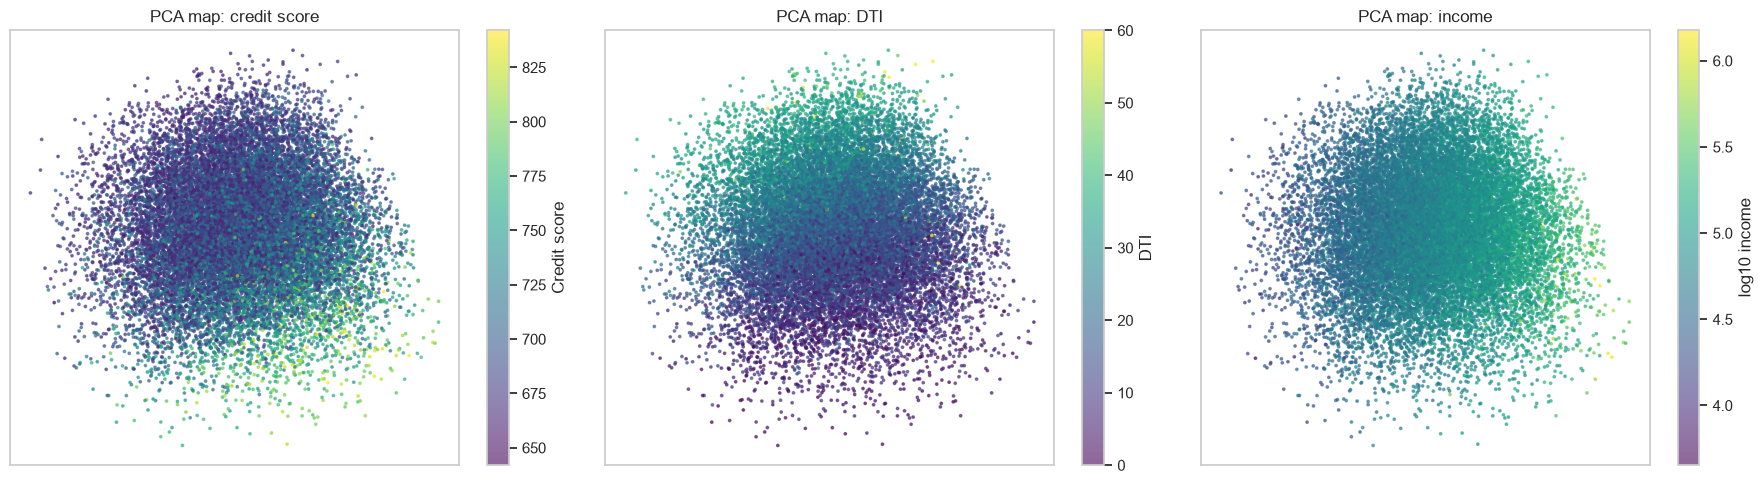

In [3]:
sample = df.iloc[sample_idx]
pca_map = X_pca[sample_idx][:, :2]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
draw_map(axes[0], pca_map, sample["CreditScore"], "PCA map: credit score", "Credit score")
draw_map(axes[1], pca_map, sample["DTI"].clip(upper=60), "PCA map: DTI", "DTI")
draw_map(axes[2], pca_map, np.log10(sample["Income"]), "PCA map: income", "log10 income")
plt.tight_layout()
plt.savefig("../docs/figures/11_pca_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
tsne_idx = sample_idx[:10_000]

tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42)
tsne_embedding = tsne.fit_transform(X_pca[tsne_idx])
print(tsne_embedding.shape)

(10000, 2)


In [5]:
import umap

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
umap_embedding = reducer.fit_transform(X_pca[sample_idx])
print(umap_embedding.shape)

c:\Users\yoges\credit-portfolio-segmentation\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\yoges\credit-portfolio-segmentation\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(20000, 2)


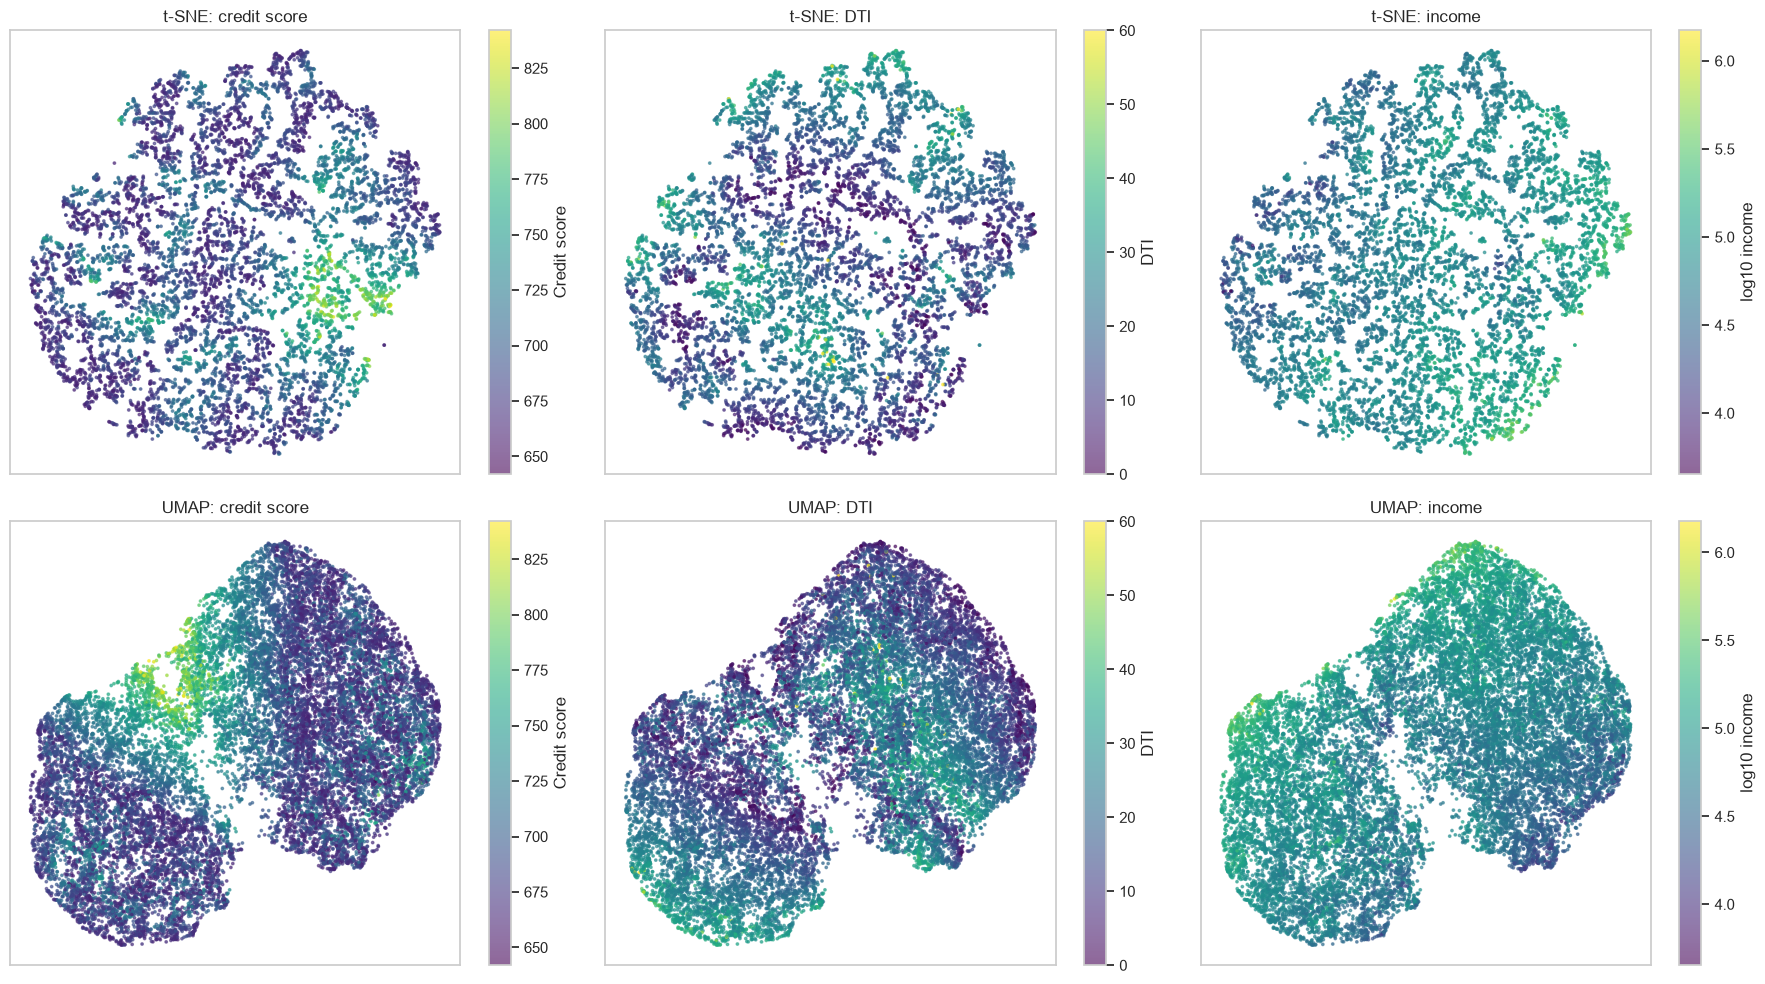

In [6]:
tsne_sample = df.iloc[tsne_idx]
umap_sample = df.iloc[sample_idx]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
maps = [("t-SNE", tsne_embedding, tsne_sample), ("UMAP", umap_embedding, umap_sample)]
for row, (name, embedding, rows) in enumerate(maps):
    draw_map(axes[row, 0], embedding, rows["CreditScore"], f"{name}: credit score", "Credit score")
    draw_map(axes[row, 1], embedding, rows["DTI"].clip(upper=60), f"{name}: DTI", "DTI")
    draw_map(axes[row, 2], embedding, np.log10(rows["Income"]), f"{name}: income", "log10 income")
plt.tight_layout()
plt.savefig("../docs/figures/12_tsne_umap_maps.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
np.save("../data/processed/tsne_embedding.npy", tsne_embedding)
np.save("../data/processed/umap_embedding.npy", umap_embedding)